In [1]:
from dotenv import load_dotenv
load_dotenv()

from langchain_openai import ChatOpenAI

llm = ChatOpenAI(model="gpt-5.4-mini", stream_usage=True,temperature=0.7)


In [2]:
from pydantic import BaseModel,Field

class graphSchema(BaseModel):
    topic:str
    insta:str
    twitter:str
    linkedIn:str

In [12]:
def create_insta_post(state:graphSchema) -> graphSchema:
    
    topic=state.topic
    post=llm.invoke(f"create a insta post about {topic} and make teh content more engaging").content
    state.insta=post

    return {"insta":post}


def create_twitter_post(state:graphSchema) -> graphSchema:
    
    topic=state.topic
    post=llm.invoke(f"create a twitter post about {topic} and make teh content more casual").content
    state.twitter=post

    return {"twitter":post}

def create_linkedIn_post(state:graphSchema) -> graphSchema:
    
    topic=state.topic
    post=llm.invoke(f"create a linkedIn post about {topic} and make the content more informative and proffessional").content
    state.linkedIn=post

    return {"linkedIn":post}




In [13]:
from langgraph.graph import StateGraph, START, END

graph=StateGraph(graphSchema)

graph.add_node('create_insta_post',create_insta_post)
graph.add_node('create_twitter_post', create_twitter_post)
graph.add_node('create_linkedIn_post', create_linkedIn_post)


graph.add_edge(START,"create_insta_post")
graph.add_edge("create_insta_post",END)
graph.add_edge(START,"create_twitter_post")
graph.add_edge("create_twitter_post",END)
graph.add_edge(START,"create_linkedIn_post")
graph.add_edge("create_linkedIn_post",END)



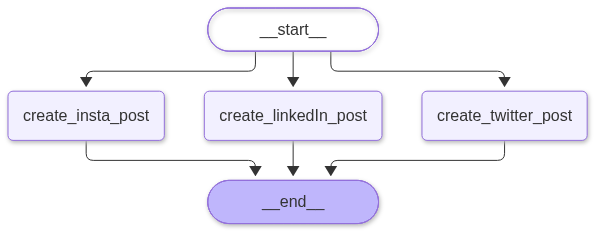

In [14]:
## compile the graph 

from IPython.display import Image, display

parallelization_graph=graph.compile()


Image(parallelization_graph.get_graph().draw_mermaid_png())

In [15]:
parallelization_graph.invoke({
    "topic":"talk about fifa world cup final 2026 and why did argentina lose the match",
     "insta":"", 
     "twitter":"",
     "linkedIn":""})

{'topic': 'talk about fifa world cup final 2026 and why did argentina lose the match',
 'insta': 'Sure — here’s an engaging Instagram post caption you can use:\n\n---\n\n🏆 **FIFA World Cup Final 2026: What Went Wrong for Argentina?** 🇦🇷💔\n\nThe final was a rollercoaster, and Argentina fought with heart, passion, and everything they had — but in the end, it just wasn’t enough. ⚽🔥\n\nSo why did Argentina lose?\n\n👉 **Missed chances:** Big moments came, but the finishing touch wasn’t there.  \n👉 **Midfield pressure:** The opponent controlled key areas and broke Argentina’s rhythm.  \n👉 **Defensive gaps:** A few small mistakes turned into costly chances.  \n👉 **Fatigue & pressure:** Finals are brutal — and every second counts.\n\nStill, Argentina gave us a match full of emotion, drama, and unforgettable moments. 💙🤍  \nChampions don’t just win trophies — they inspire millions. And Argentina did exactly that.\n\nWhat do you think was the biggest reason for the loss? Drop your thoughts below!